# ** CIFAR-10 Image Classification Using Deep Learning (CNN)**

In [17]:
# Step 1: Import required libraries

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import random

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
# Download and load CIFAR-10 training dataset

train_data = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True
)

# Download and load CIFAR-10 testing dataset

test_data = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

# Get all class names
classes = train_data.classes

print("Classes:", classes)

Training images: 50000
Testing images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


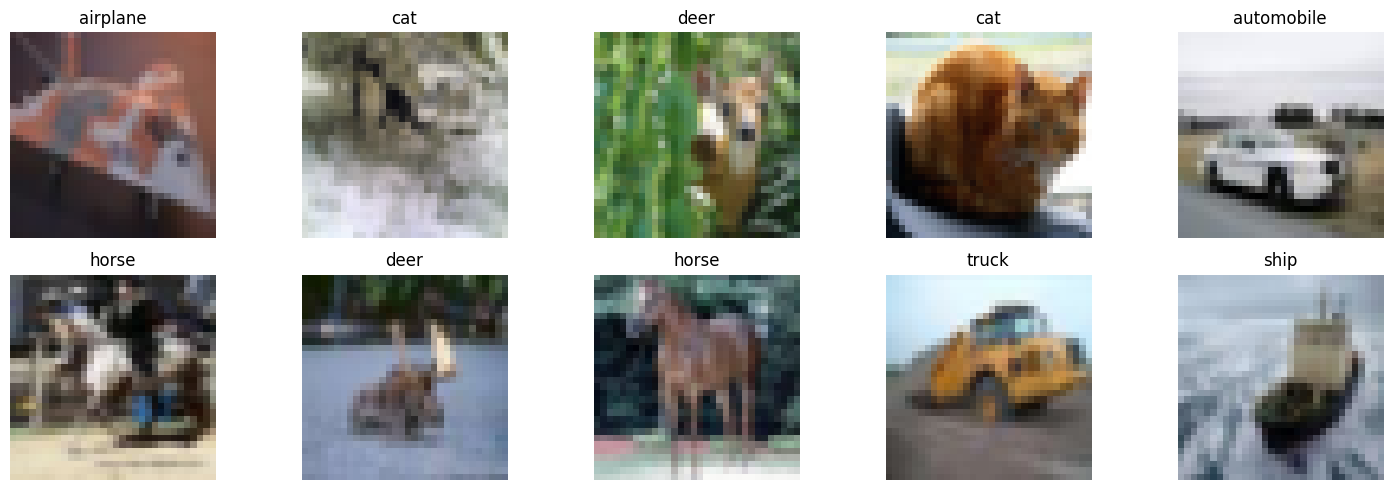

In [19]:
# Create a figure containing 10 images

plt.figure(figsize=(15, 5))

# Select 10 random image indexes
random_indexes = random.sample(range(len(train_data)), 10)

for i, index in enumerate(random_indexes):

    # Get image and label
    image, label = train_data[index]

    # Create subplot
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(image)

    # Display class name
    plt.title(classes[label])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [20]:
# Convert images into tensors and normalize to [0, 1]

transform = transforms.ToTensor()

# Apply transformation to training data
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Apply transformation to testing data
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Check one image
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())
print("Label:", classes[label])

Image shape: torch.Size([3, 32, 32])
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Label: frog


In [21]:
# Define training transformations

train_transform = transforms.Compose([

    # Randomly flip image horizontally
    transforms.RandomHorizontalFlip(p=0.5),

    # Rotate image between -15 and +15 degrees
    transforms.RandomRotation(15),

    # Shift image slightly in horizontal and vertical directions
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),

    # Convert image into tensor [0, 1]
    transforms.ToTensor()
])


# Testing data: No random augmentation
test_transform = transforms.ToTensor()


# Load augmented training dataset

train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=train_transform
)


# Load testing dataset

test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=test_transform
)

print("Augmentation applied successfully!")

Augmentation applied successfully!


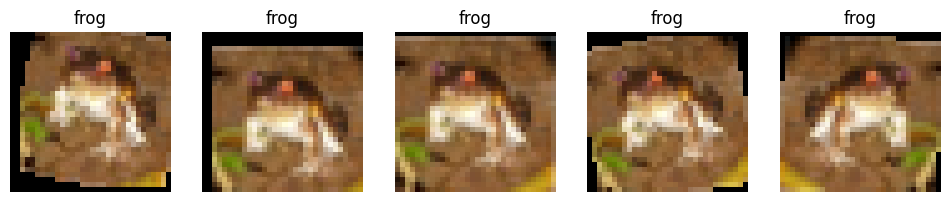

In [22]:
# Select one image
image, label = train_data[0]

plt.figure(figsize=(12, 4))

# Apply transformations multiple times
for i in range(5):

    augmented_image = train_transform(image)

    # Convert tensor to image format for display
    display_image = augmented_image.permute(1, 2, 0)

    plt.subplot(1, 5, i + 1)
    plt.imshow(display_image)
    plt.title(classes[label])
    plt.axis('off')

plt.show()

In [23]:
import torchvision
import torchvision.transforms as transforms

# Training transformation
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),
    transforms.ToTensor()
])

# Testing transformation
test_transform = transforms.ToTensor()

# Create training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=train_transform
)

# Create testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=test_transform
)

print("Datasets created successfully!")

Datasets created successfully!


In [24]:
# Check dataset size
print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))

# Check image and label
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", train_dataset.classes[label])

print("Minimum pixel:", image.min().item())
print("Maximum pixel:", image.max().item())

Training dataset: 50000
Testing dataset: 10000
Image shape: torch.Size([3, 32, 32])
Label: frog
Minimum pixel: 0.0
Maximum pixel: 1.0


# **PHASE 2**

In [25]:
# PyTorch libraries
import torch
import torch.nn as nn
import torch.optim as optim

# DataLoader
from torch.utils.data import DataLoader, Subset

# Dataset and transformations
import torchvision
import torchvision.transforms as transforms

# Other libraries
import numpy as np
import matplotlib.pyplot as plt

# Evaluation libraries
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [26]:
# Check whether GPU is available

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Available device:", device)

Available device: cpu


In [27]:
# Training transformations
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),
    transforms.ToTensor()
])

# Validation and testing transformations
test_transform = transforms.ToTensor()


# Load augmented training dataset
train_augmented = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=train_transform
)

# Load non-augmented dataset for validation
train_original = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=test_transform
)

# Split indexes into training and validation
indices = np.arange(len(train_augmented))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.1,
    random_state=42,
    stratify=train_augmented.targets
)

# Create separate datasets
train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_original, val_indices)

# Load testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=test_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 45000
Validation images: 5000
Testing images: 10000


In [28]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [29]:
class DeepCNN(nn.Module):

    def __init__(self):
        super(DeepCNN, self).__init__()

        # Block 1: 3 input channels -> 32 filters
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.2)
        )

        # Block 2: 32 -> 64 filters
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.2)
        )

        # Block 3: 64 -> 128 filters
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.3)
        )

        # Block 4: 128 -> 128 filters
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.3)
        )

        # Fully connected layers
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 2 * 2, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 10)
        )

    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.fc(x)

        return x


# Create model
model = DeepCNN().to(device)

print(model)

DeepCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.2, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.2, inplace=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
   

In [30]:
# Define loss function
criterion = nn.CrossEntropyLoss()

# Define Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [7]:
# Number of training epochs
epochs = 25

# Store training and validation results
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# Best validation accuracy
best_accuracy = 0.0


for epoch in range(epochs):

    # ---------------- TRAINING ----------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move data to GPU or CPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward propagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Calculate total loss
        running_loss += loss.item()

        # Get predicted class
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Calculate training loss and accuracy
    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = 100 * correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)


    # ---------------- VALIDATION ----------------

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    # No gradient calculation during validation
    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    # Calculate validation results
    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = 100 * val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)


    # Save best model
    if epoch_val_acc > best_accuracy:

        best_accuracy = epoch_val_acc

        torch.save(
            model.state_dict(),
            "best_cifar10_model.pth"
        )


    # Display epoch results
    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"Train Loss: {epoch_train_loss:.4f}")
    print(f"Train Accuracy: {epoch_train_acc:.2f}%")
    print(f"Validation Loss: {epoch_val_loss:.4f}")
    print(f"Validation Accuracy: {epoch_val_acc:.2f}%")
    print("-" * 45)


print("Training completed!")
print("Best Validation Accuracy:", best_accuracy)

Epoch [1/25]
Train Loss: 1.7938
Train Accuracy: 33.78%
Validation Loss: 1.4007
Validation Accuracy: 48.60%
---------------------------------------------
Epoch [2/25]
Train Loss: 1.5657
Train Accuracy: 42.86%
Validation Loss: 1.2582
Validation Accuracy: 53.02%
---------------------------------------------
Epoch [3/25]
Train Loss: 1.4569
Train Accuracy: 47.03%
Validation Loss: 1.1512
Validation Accuracy: 57.66%
---------------------------------------------
Epoch [4/25]
Train Loss: 1.3844
Train Accuracy: 49.73%
Validation Loss: 1.0810
Validation Accuracy: 60.48%
---------------------------------------------
Epoch [5/25]
Train Loss: 1.3238
Train Accuracy: 52.09%
Validation Loss: 1.0012
Validation Accuracy: 63.64%
---------------------------------------------
Epoch [6/25]
Train Loss: 1.2742
Train Accuracy: 54.24%
Validation Loss: 1.2628
Validation Accuracy: 54.26%
---------------------------------------------
Epoch [7/25]
Train Loss: 1.2342
Train Accuracy: 55.77%
Validation Loss: 1.0998
Val

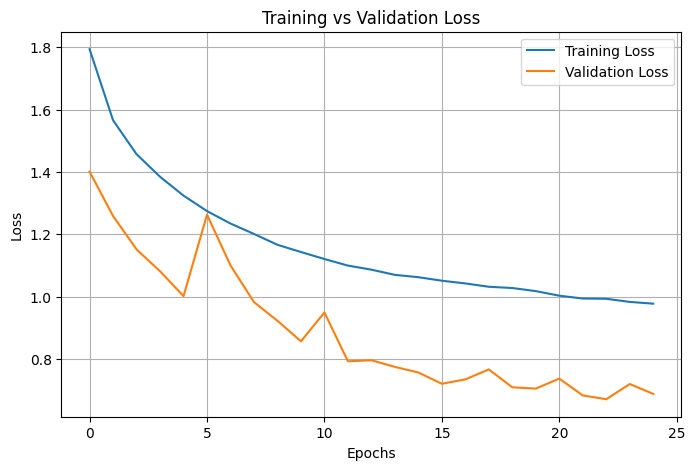

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.title('Training vs Validation Loss')

plt.legend()
plt.grid()

plt.show()

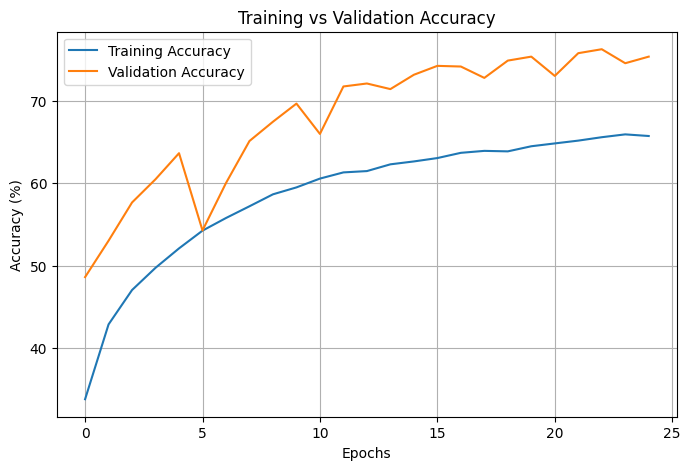

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')

plt.title('Training vs Validation Accuracy')

plt.legend()
plt.grid()

plt.show()

In [33]:
# Load the best saved model

model.load_state_dict(
    torch.load(
        "best_cifar10_model.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [34]:
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Predict images
        outputs = model(images)

        # Get predicted classes
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

        # Store predictions and actual labels
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# Calculate accuracy
test_accuracy = 100 * correct / total

print(f"Final Test Accuracy: {test_accuracy:.2f}%")

Final Test Accuracy: 75.89%


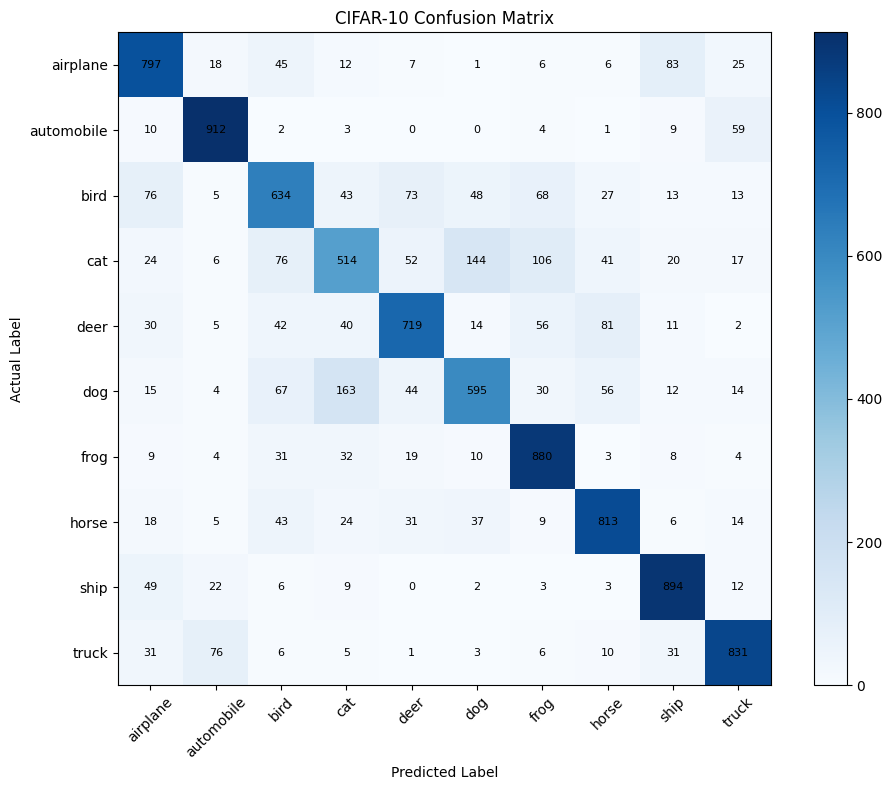

In [35]:
# Calculate confusion matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

# Display confusion matrix
plt.figure(figsize=(10, 8))

plt.imshow(cm, cmap='Blues')

plt.title("CIFAR-10 Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(range(10), test_dataset.classes, rotation=45)
plt.yticks(range(10), test_dataset.classes)

plt.colorbar()

# Display values inside matrix
for i in range(10):
    for j in range(10):
        plt.text(
            j, i,
            cm[i, j],
            ha='center',
            va='center',
            fontsize=8
        )

plt.tight_layout()
plt.show()

In [36]:
print("Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.classes
    )
)

Classification Report:

              precision    recall  f1-score   support

    airplane       0.75      0.80      0.77      1000
  automobile       0.86      0.91      0.89      1000
        bird       0.67      0.63      0.65      1000
         cat       0.61      0.51      0.56      1000
        deer       0.76      0.72      0.74      1000
         dog       0.70      0.59      0.64      1000
        frog       0.75      0.88      0.81      1000
       horse       0.78      0.81      0.80      1000
        ship       0.82      0.89      0.86      1000
       truck       0.84      0.83      0.83      1000

    accuracy                           0.76     10000
   macro avg       0.75      0.76      0.75     10000
weighted avg       0.75      0.76      0.75     10000



In [37]:
# Save final trained model

torch.save(
    model.state_dict(),
    "cifar10_final_model.pth"
)

print("Final model saved successfully!")

Final model saved successfully!


In [38]:
from google.colab import files

files.download("cifar10_final_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **PHASE 3**

In [39]:
!pip install gradio

In [40]:
torch.save(
    model.state_dict(),
    "best_cifar10_model.pth"
)

In [41]:
import os

if os.path.exists("best_cifar10_model.pth"):
    print("Model file found!")
else:
    print("Model file not found!")

Model file found!


In [42]:
import torch
import torch.nn as nn

# Define CNN architecture
class DeepCNN(nn.Module):

    def __init__(self):
        super(DeepCNN, self).__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.3)
        )

        self.block4 = nn.Sequential(
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.3)
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 2 * 2, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 10)
        )

    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.fc(x)

        return x


print("CNN architecture defined successfully!")

CNN architecture defined successfully!


In [43]:
# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create model
model = DeepCNN().to(device)

# Load trained weights
model.load_state_dict(
    torch.load(
        "best_cifar10_model.pth",
        map_location=device,
        weights_only=True
    )
)

# Set model to evaluation mode
model.eval()

print("Trained CNN model loaded successfully!")

Trained CNN model loaded successfully!


In [44]:
classes = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]

print("Classes loaded successfully!")

Classes loaded successfully!


In [45]:
from PIL import Image
import torchvision.transforms as transforms

# Image preprocessing
preprocess = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

print("Preprocessing pipeline ready!")

Preprocessing pipeline ready!


In [46]:
def predict_image(image):

    # Convert image into RGB
    image = image.convert("RGB")

    # Resize and convert image into tensor
    image_tensor = preprocess(image)

    # Add batch dimension
    image_tensor = image_tensor.unsqueeze(0)

    # Move image to GPU or CPU
    image_tensor = image_tensor.to(device)

    # Disable gradient calculation
    with torch.no_grad():

        # Get model predictions
        outputs = model(image_tensor)

        # Convert logits into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Get highest confidence class
        confidence, predicted_class = torch.max(
            probabilities, dim=1
        )

    # Get predicted class name
    predicted_name = classes[predicted_class.item()]

    # Create confidence dictionary
    confidence_scores = {
        classes[i]: float(probabilities[0][i].item())
        for i in range(10)
    }

    return predicted_name, confidence.item(), confidence_scores

In [47]:
!pip install -q --upgrade gradio

In [48]:
import gradio as gr
import pandas as pd

print("Gradio is ready!")

Gradio is ready!


In [49]:
def classify_image(image):

    # Check whether image is uploaded
    if image is None:
        return None, "Please upload an image!", {}, pd.DataFrame()

    # Keep original image for preview
    original_image = image.convert("RGB")

    # Preprocess image
    image_tensor = preprocess(original_image)

    # Add batch dimension
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Model prediction
    with torch.no_grad():

        outputs = model(image_tensor)

        # Convert logits into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Get predicted class
        confidence, predicted_class = torch.max(
            probabilities, dim=1
        )

    # Predicted class name
    predicted_name = classes[predicted_class.item()]

    # Confidence percentage
    confidence_value = confidence.item() * 100

    # All 10 confidence scores
    scores = {
        classes[i]: float(probabilities[0][i].item())
        for i in range(10)
    }

    # Create DataFrame for bar chart
    chart_data = pd.DataFrame({
        "Class": classes,
        "Confidence": [
            probabilities[0][i].item() * 100
            for i in range(10)
        ]
    })

    # Sort confidence from highest to lowest
    chart_data = chart_data.sort_values(
        by="Confidence",
        ascending=False
    )

    # Prediction result
    result = f"{predicted_name} ({confidence_value:.2f}%)"

    return original_image, result, scores, chart_data

In [50]:
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # CIFAR-10 Image Classification
        ### Deep Learning Based CNN Model

        Upload an image to predict its class.
        """
    )

    with gr.Row():

        # Image uploader
        input_image = gr.Image(
            type="pil",
            label="Upload Image",
            sources=["upload"]
        )

        # Display uploaded image
        preview_image = gr.Image(
            label="Uploaded Image Preview"
        )

    # Prediction output
    prediction_output = gr.Textbox(
        label="Predicted Class",
        interactive=False
    )

    # Confidence scores
    confidence_output = gr.Label(
        label="Class Confidence Scores",
        num_top_classes=10
    )

    # Confidence bar chart
    confidence_chart = gr.BarPlot(
        x="Class",
        y="Confidence",
        title="Confidence Scores for All 10 Classes",
        y_title="Confidence (%)",
        x_title="CIFAR-10 Classes"
    )

    # Predict button
    predict_button = gr.Button(
        "Predict Image",
        variant="primary"
    )

    # Connect button with prediction function
    predict_button.click(
        fn=classify_image,
        inputs=input_image,
        outputs=[
            preview_image,
            prediction_output,
            confidence_output,
            confidence_chart
        ]
    )


# Launch application
demo.launch(share=True)

/tmp/ipykernel_15449/2038692994.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://906b16b8e1beaa2f10.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [52]:
from google.colab import files

files.download("best_cifar10_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>